# Preprocessing and feature engineering

This notebook uses the inspected dataset columns only. Its target is `fraudulent` (`f` = legitimate, `t` = fraudulent); text fields are `title`, `company_profile`, `description`, `requirements`, and `benefits`. Metadata columns are checked against the loaded CSV before use.

Exact duplicate rows are removed. Rule-based cleanup and indicators are deterministic. Before fitting learned transformations, the notebook makes a stratified 80/20 split. Imputers, `OneHotEncoder`, and `StandardScaler` are fitted only on the training rows, then transform both partitions. No model is trained and no resampling is performed.

The encoded output uses `min_frequency=10` to group rare categories and remain practical, along with `handle_unknown='ignore'`. The one-hot matrix remains sparse until chunked CSV output.

Loaded 17,880 rows; removed 235 exact duplicates; 17,645 rows remain.
Exact columns: ['title', 'location', 'department', 'salary_range', 'company_profile', 'description', 'requirements', 'benefits', 'telecommuting', 'has_company_logo', 'has_questions', 'employment_type', 'required_experience', 'required_education', 'industry', 'function', 'fraudulent', 'in_balanced_dataset']


,missing_count_before_imputation
salary_range,14813
department,11368
required_education,8028
benefits,7103
required_experience,6976
function,6378
industry,4849
employment_type,3435
company_profile,3287
requirements,2650


Text fields combined: ['title', 'company_profile', 'description', 'requirements', 'benefits']


,combined_text,description_length,requirements_length,word_count,character_count,url_count,email_count,phone_count,exclamation_count,missing_company_profile,contains_urgent_language,contains_fee_request,contains_easy_money,contains_no_experience,contains_work_from_home,contains_cryptocurrency_payment,contains_whatsapp_or_telegram
0,"marketing intern we're food52, and we've creat...",1002,984,417,2681,0,0,0,1,0,0,0,0,0,0,0,0
1,customer service - cloud video production 90 s...,2175,1851,933,5780,9,0,0,5,0,0,0,0,0,0,0,0
2,commissioning machinery assistant (cma) valor ...,362,1540,384,2653,0,0,0,0,0,0,0,0,0,0,0,0


Stratified split class proportions (% within partition):


fraudulent,f,t
split,,
test,95.13,4.87
train,95.14,4.86


One-hot columns: 480; scaled numeric columns: 16
Sparse feature matrix: (17645, 496)


Saved 17,645 rows x 515 columns to data\processed\processed_job_postings.csv
CSV size: 83.9 MiB
Feature means and medians by class:


class_label,feature,statistic,Fraudulent (t),Legitimate (f)
0,description_length,mean,1438.8252,1439.3646
1,description_length,median,972.5000,1166.0000
2,requirements_length,mean,514.3473,744.0926
3,requirements_length,median,294.0000,575.0000
4,word_count,mean,300.2063,406.0094
5,word_count,median,248.5000,380.0000
6,character_count,mean,2085.6142,2700.9891
7,character_count,median,1662.5000,2568.0000
8,url_count,mean,0.1737,0.0492
9,url_count,median,0.0000,0.0000


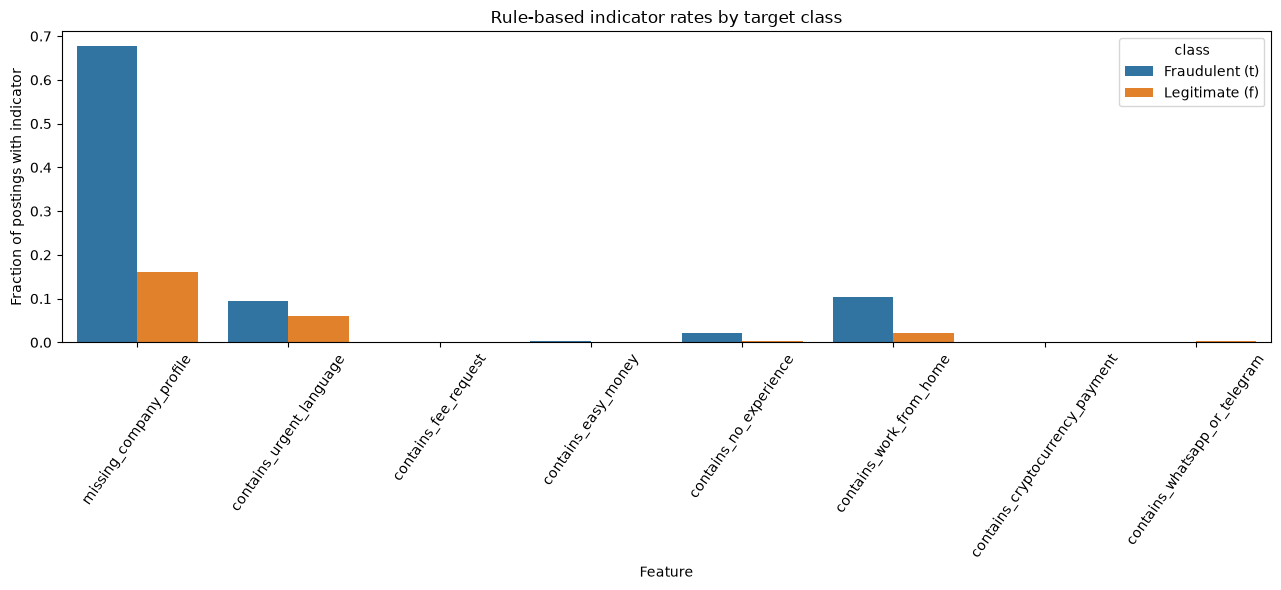

Saved report: report\feature_engineering_report.md
Saved feature plot: report\feature_distributions_by_class.png
Saved processed CSV: data\processed\processed_job_postings.csv (88,010,868 bytes)


In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy import sparse
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent
elif PROJECT_DIR.name != "fake-job-detector" and (PROJECT_DIR / "fake-job-detector").is_dir():
    PROJECT_DIR = PROJECT_DIR / "fake-job-detector"

RAW_PATH = PROJECT_DIR / "data" / "raw" / "DataSet.csv"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
REPORT_DIR = PROJECT_DIR / "report"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)
if not RAW_PATH.is_file():
    raise FileNotFoundError(f"Inspected source CSV not found: {RAW_PATH}")

df = pd.read_csv(RAW_PATH, low_memory=False)
target = "fraudulent"
if target not in df.columns:
    raise KeyError(f"Expected inspected target {target!r}; found {df.columns.tolist()}")
labels = df[target].dropna().astype(str).str.strip().str.lower()
if set(labels.unique()) != {"f", "t"}:
    raise ValueError(f"Unexpected target labels: {sorted(labels.unique())}")

rows_before = len(df)
df = df.drop_duplicates().copy()
duplicates_removed = rows_before - len(df)
# Empty/whitespace-only values are missing, not meaningful categories.
for column in df.select_dtypes(include=["object", "string"]).columns:
    df[column] = df[column].replace(r"^\s*$", pd.NA, regex=True)
missing_counts = df.isna().sum().sort_values(ascending=False)
print(f"Loaded {rows_before:,} rows; removed {duplicates_removed:,} exact duplicates; {len(df):,} rows remain.")
print("Exact columns:", df.columns.tolist())
display(missing_counts.rename("missing_count_before_imputation").to_frame())

# These text fields were observed in the inspection report. Ignore any absent optional field.
text_candidates = ["title", "company_profile", "description", "requirements", "benefits"]
text_columns = [column for column in text_candidates if column in df.columns]
if not text_columns:
    raise ValueError("No inspected posting text fields were found in the CSV.")
def safe_text(value):
    return "" if pd.isna(value) else str(value)

raw_text = df[text_columns].fillna("").astype(str).agg(" ".join, axis=1)
def clean_text(value):
    text = safe_text(value).lower()
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"\b(?:https?://|www\.)\S+", " URL ", text, flags=re.IGNORECASE)
    text = re.sub(r"\b[\w.+%-]+@[\w.-]+\.[a-z]{2,}\b", " EMAIL ", text, flags=re.IGNORECASE)
    return re.sub(r"\s+", " ", text).strip()

df["combined_text"] = raw_text.map(clean_text)
description = df["description"].map(safe_text) if "description" in df.columns else pd.Series("", index=df.index)
requirements = df["requirements"].map(safe_text) if "requirements" in df.columns else pd.Series("", index=df.index)
company_profile = df["company_profile"].map(safe_text) if "company_profile" in df.columns else pd.Series("", index=df.index)

url_re = r"\b(?:https?://|www\.)\S+"
email_re = r"\b[\w.+%-]+@[\w.-]+\.[a-z]{2,}\b"
phone_re = r"(?<!\w)(?:\+?\d[\d().\s-]{5,}\d)(?!\w)"
patterns = {
    "contains_urgent_language": r"\b(?:urgent(?:ly)?|asap|immediately|hiring now|start immediately)\b",
    "contains_fee_request": r"\b(?:application|processing|registration|upfront|training)\s+fees?\b|\bpay\s+(?:an?\s+)?(?:application\s+)?fee\b|\bdeposit required\b",
    "contains_easy_money": r"\b(?:easy money|quick cash|earn money fast|get rich(?: quick)?|guaranteed income)\b",
    "contains_no_experience": r"\bno (?:previous )?experience (?:required|needed|necessary)\b",
    "contains_work_from_home": r"\bwork[- ]from[- ]home\b|\bremote work\b|\bwork remotely\b",
    "contains_cryptocurrency_payment": r"\b(?:bitcoin|crypto(?:currency)?)\b.{0,40}\b(?:pay(?:ment)?|paid|salary|wage|compensation)\b|\b(?:pay(?:ment)?|paid|salary|wage|compensation)\b.{0,40}\b(?:bitcoin|crypto(?:currency)?)\b",
    "contains_whatsapp_or_telegram": r"\bwhats\s?app\b|\btelegram\b",
}
features = pd.DataFrame(index=df.index)
features["description_length"] = description.str.len()
features["requirements_length"] = requirements.str.len()
features["word_count"] = df["combined_text"].str.findall(r"\b\w+\b").str.len()
features["character_count"] = df["combined_text"].str.len()
features["url_count"] = raw_text.map(lambda text: len(re.findall(url_re, text, flags=re.IGNORECASE)))
features["email_count"] = raw_text.map(lambda text: len(re.findall(email_re, text, flags=re.IGNORECASE)))
features["phone_count"] = raw_text.map(lambda text: len(re.findall(phone_re, text)))
features["exclamation_count"] = raw_text.str.count("!")
features["missing_company_profile"] = company_profile.str.strip().eq("").astype(int)
for feature_name, pattern in patterns.items():
    features[feature_name] = df["combined_text"].map(lambda text: int(bool(re.search(pattern, text, re.IGNORECASE))))
numeric_features = features.columns.tolist()
df = df.join(features)
print("Text fields combined:", text_columns)
display(df[["combined_text", *numeric_features]].head(3))

# Only use metadata columns observed in the inspection report and present in this CSV.
categorical_candidates = [
    "location", "department", "salary_range", "employment_type",
    "required_experience", "required_education", "industry", "function",
    "telecommuting", "has_company_logo", "has_questions",
]
categorical_features = [column for column in categorical_candidates if column in df.columns]
# Exclude the label and the sampling/provenance field from predictors.
categorical_features = [column for column in categorical_features if column not in {target, "in_balanced_dataset"}]
y = df[target].astype(str).str.strip().str.lower()
train_idx, test_idx = train_test_split(
    df.index.to_numpy(), test_size=0.20, random_state=42, stratify=y
)
split = pd.Series("train", index=df.index, name="split")
split.loc[test_idx] = "test"
split_distribution = pd.crosstab(split, y, normalize="index").mul(100).round(2)
print("Stratified split class proportions (% within partition):")
display(split_distribution)

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="__MISSING__")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=10, sparse_output=True, dtype=np.float32)),
])
# Fit only on training rows. Test rows use these same fitted values/categories/scaling.
numeric_pipeline.fit(features.loc[train_idx, numeric_features])
categorical_pipeline.fit(df.loc[train_idx, categorical_features])
numeric_all = numeric_pipeline.transform(features[numeric_features])
categorical_all = categorical_pipeline.transform(df[categorical_features])
onehot_source_names = categorical_pipeline.named_steps["onehot"].get_feature_names_out(categorical_features).tolist()
# Indexed names avoid duplicate CSV headers when categories differ only by letter case.
onehot_names = [f"ohe__{index:04d}" for index in range(len(onehot_source_names))]
mapping_path = PROCESSED_DIR / "onehot_feature_mapping.csv"
pd.DataFrame({"encoded_column": onehot_names, "source_feature_category": onehot_source_names}).to_csv(mapping_path, index=False)
scaled_names = [f"scaled__{name}" for name in numeric_features]
all_matrix = sparse.hstack([categorical_all, sparse.csr_matrix(numeric_all)], format="csr")
encoded_names = onehot_names + scaled_names
print(f"One-hot columns: {len(onehot_names):,}; scaled numeric columns: {len(scaled_names)}")
print(f"Sparse feature matrix: {all_matrix.shape}")

# Store both raw engineered values for interpretation and train-fitted transformed features.
metadata = df[["combined_text", target]].copy()
metadata["split"] = split
raw_features = features.add_prefix("raw__")
scaled_features = pd.DataFrame(numeric_all, index=df.index, columns=scaled_names)
encoded_categories = pd.DataFrame.sparse.from_spmatrix(
    categorical_all, index=df.index, columns=onehot_names
)
processed = pd.concat([metadata, raw_features, scaled_features, encoded_categories], axis=1)
output_path = PROCESSED_DIR / "processed_job_postings.csv"
processed.to_csv(output_path, index=False, chunksize=500)
print(f"Saved {len(processed):,} rows x {processed.shape[1]:,} columns to {output_path.relative_to(PROJECT_DIR)}")
print(f"CSV size: {output_path.stat().st_size / (1024 ** 2):.1f} MiB")

# Descriptive feature comparisons use original units; binary feature means are positive rates.
class_names = {"f": "Legitimate (f)", "t": "Fraudulent (t)"}
class_counts = y.value_counts().rename(index=class_names)
comparison = features.assign(class_label=y.map(class_names)).groupby("class_label")[numeric_features].agg(["mean", "median"]).T
comparison.index.names = ["feature", "statistic"]
comparison = comparison.reset_index().round(4)
print("Feature means and medians by class:")
display(comparison)

indicator_features = [name for name in numeric_features if name.startswith("contains_") or name == "missing_company_profile"]
rate_data = features[indicator_features].assign(class_label=y.map(class_names)).groupby("class_label").mean().T
rate_data = rate_data.reset_index(names="feature").melt(id_vars="feature", var_name="class", value_name="positive_rate")
fig, ax = plt.subplots(figsize=(13, 6))
sns.barplot(data=rate_data, x="feature", y="positive_rate", hue="class", ax=ax)
ax.set_title("Rule-based indicator rates by target class")
ax.set_xlabel("Feature")
ax.set_ylabel("Fraction of postings with indicator")
ax.tick_params(axis="x", rotation=55)
fig.tight_layout()
plot_path = REPORT_DIR / "feature_distributions_by_class.png"
fig.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.show()

def markdown_table(frame):
    values = frame.fillna("").astype(str).apply(lambda column: column.str.replace("|", r"\|", regex=False))
    headers = [str(column) for column in values.columns]
    lines = ["| " + " | ".join(headers) + " |", "| " + " | ".join("---" for _ in headers) + " |"]
    lines.extend("| " + " | ".join(row) + " |" for row in values.to_numpy().tolist())
    return "\n".join(lines)

feature_mean = features.assign(class_label=y).groupby("class_label")[numeric_features].mean().T.round(4)
feature_mean.columns = [class_names[label] for label in feature_mean.columns]
feature_mean.index.name = "feature"
feature_mean = feature_mean.reset_index()
explanations = [
    ("description_length", "Description character count; gives context about how much information is supplied."),
    ("requirements_length", "Requirements character count; short or vague requirements may merit review."),
    ("word_count", "Word-like tokens in cleaned combined text; measures text volume."),
    ("character_count", "Characters in cleaned combined text; another measure of information volume."),
    ("url_count", "URLs in original text; helps surface external links for review."),
    ("email_count", "Email addresses in original text; captures direct contact details."),
    ("phone_count", "Phone-like digit sequences; captures direct contact, but can include false matches."),
    ("exclamation_count", "Exclamation marks; may capture highly promotional or urgent tone."),
    ("missing_company_profile", "One when company_profile is blank; indicates limited employer context."),
    ("contains_urgent_language", "Urgent/ASAP/immediately/hiring-now phrases; may indicate pressure to act quickly."),
    ("contains_fee_request", "Common applicant fee or deposit phrases; payment requests merit scrutiny."),
    ("contains_easy_money", "Easy-money/quick-cash/guaranteed-income wording; captures unrealistic earning claims."),
    ("contains_no_experience", "No-experience-required wording; occurs in legitimate entry-level jobs too."),
    ("contains_work_from_home", "Work-from-home or remote wording; context, not a fraud verdict."),
    ("contains_cryptocurrency_payment", "Crypto mentioned near payment/salary; captures potentially unusual payment method."),
    ("contains_whatsapp_or_telegram", "WhatsApp/Telegram mention; helps review requests to move off-platform."),
]
explanation_table = pd.DataFrame(explanations, columns=["feature", "meaning_and_possible_use"])
missing_table = pd.DataFrame({"column": missing_counts.index.astype(str), "missing_count": missing_counts.values})
report_lines = [
    "# Feature Engineering Report", "",
    "## Dataset and duplicates", "",
    f"- Source: `data/raw/{RAW_PATH.name}`",
    f"- Rows before deduplication: {rows_before:,}",
    f"- Exact duplicate rows removed: {duplicates_removed:,}",
    f"- Rows after deduplication: {len(df):,}",
    f"- Target: `{target}`; `f` = legitimate, `t` = fraudulent.",
    "- Class distribution after deduplication:", "",
    markdown_table(class_counts.rename_axis("class").reset_index(name="count")), "",
    "## Missing-value handling", "",
    "Whitespace-only strings were changed to missing values. Text is filled with empty strings only for joining; the missing-profile indicator preserves missing company-profile information. Categorical predictors use a constant missing token; engineered numeric columns use the median learned from training rows. Optional-metadata missingness does not cause rows to be dropped.", "",
    markdown_table(missing_table), "",
    "## Text cleanup", "",
    "Available text fields: " + ", ".join(f"`{column}`" for column in text_columns) + ". Fields are concatenated; text is lowercased, HTML tags removed, URLs replaced with `URL`, email addresses with `EMAIL`, and whitespace normalized. URL/email counts use original text.", "",
    "## Engineered features and why they may help", "",
    markdown_table(explanation_table), "",
    "## Categorical encoding and numeric scaling", "",
    "Categorical predictors present and used: " + (", ".join(f"`{column}`" for column in categorical_features) or "none") + ".",
    "Categoricals use `SimpleImputer(strategy='constant')` and `OneHotEncoder(handle_unknown='ignore', min_frequency=10)`. Rare categories are grouped to keep the sparse table practical.",
    "Engineered numeric predictors use median imputation and `StandardScaler`. Imputers, encoder, and scaler are fitted on training rows only.",
    "`in_balanced_dataset` is excluded as a predictor because its provenance may reflect sampling or label construction; the target is retained only as the label.", "",
    "## Stratified split and leakage prevention", "",
    "Rows were split 80/20 with stratification and random state 42 before fitting learned transformations. The train-fitted imputers, encoder, and scaler transform both partitions. No TF-IDF, SMOTE, or model training was done.", "",
    markdown_table(split_distribution.reset_index()), "",
    "## Feature distributions by class", "",
    "The table reports mean engineered feature values for each class; for binary indicators, the mean is the positive rate. These summaries are descriptive, not evidence of causation. The plot compares indicator rates.", "",
    markdown_table(feature_mean), "",
    f"Plot: `report/{plot_path.name}`.", "",
    "## Output", "",
    f"Processed CSV: `data/processed/{output_path.name}` ({len(processed):,} rows and {processed.shape[1]:,} columns). It includes cleaned combined text, raw engineered features, scaled numeric features, uniquely named one-hot categorical features, the target, and a train/test marker.",
    f"One-hot column names map to the original feature/category in `data/processed/{mapping_path.name}`.", "",
    "## Limitations", "",
    "Regex features can have false positives and negatives. Phone-like numbers may match non-phone digit sequences. No-experience and remote-work phrases also occur in legitimate postings; no single indicator establishes fraud. The target is imbalanced, so later model evaluation should emphasize fraud precision, recall, F1, ROC-AUC, PR-AUC, and a confusion matrix rather than accuracy alone.",
]
report_path = REPORT_DIR / "feature_engineering_report.md"
report_path.write_text("\n".join(report_lines), encoding="utf-8")
print(f"Saved report: {report_path.relative_to(PROJECT_DIR)}")
print(f"Saved feature plot: {plot_path.relative_to(PROJECT_DIR)}")
print(f"Saved processed CSV: {output_path.relative_to(PROJECT_DIR)} ({output_path.stat().st_size:,} bytes)")


## Stage boundary

This notebook stops after feature engineering and train-fitted structured preprocessing. It does not train a classifier. Review the report and processed dataset before proceeding to model training.